# Attention interpretability plots

Loads `test_attention.npz` produced by `attention_interpretability.py` (run on Stellar) and plots per-frame attention weights via `plot_attention_scores`.
```

In [1]:
import sys
from io import BytesIO
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

SCRIPT_DIR = Path.cwd()
sys.path.insert(0, str(SCRIPT_DIR))
import attention_interpretability as ai


def show(fig):
    # Renders via Agg regardless of the notebook's active matplotlib backend
    # (the module forces Agg on import for cluster/headless use).
    buffer = BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    display(Image(data=buffer.getvalue()))

## Load attention data

In [2]:
SEED = 101
RESULTS_DIR = ai.engine.BASE_OUTPUT_DIR / "attention_interpretability" / f"BR_BZ_BY_JY_seed{SEED}"

data = ai.load_attention_data(RESULTS_DIR / "test_attention.npz")
metadata = pd.read_csv(RESULTS_DIR / "test_attention_metadata.csv")
print(f"{len(metadata)} test shots: " + metadata["category"].value_counts().to_dict().__repr__())
metadata.head()

173 test shots: {'tn': 141, 'tp': 14, 'fn': 11, 'fp': 7}


,Shot,label,probability,prediction,category
0,5134,0,0.010611,0,tn
1,5164,0,0.031325,0,tn
2,5165,0,0.014811,0,tn
3,5171,0,0.021147,0,tn
4,5172,0,0.018031,0,tn


## Single shot

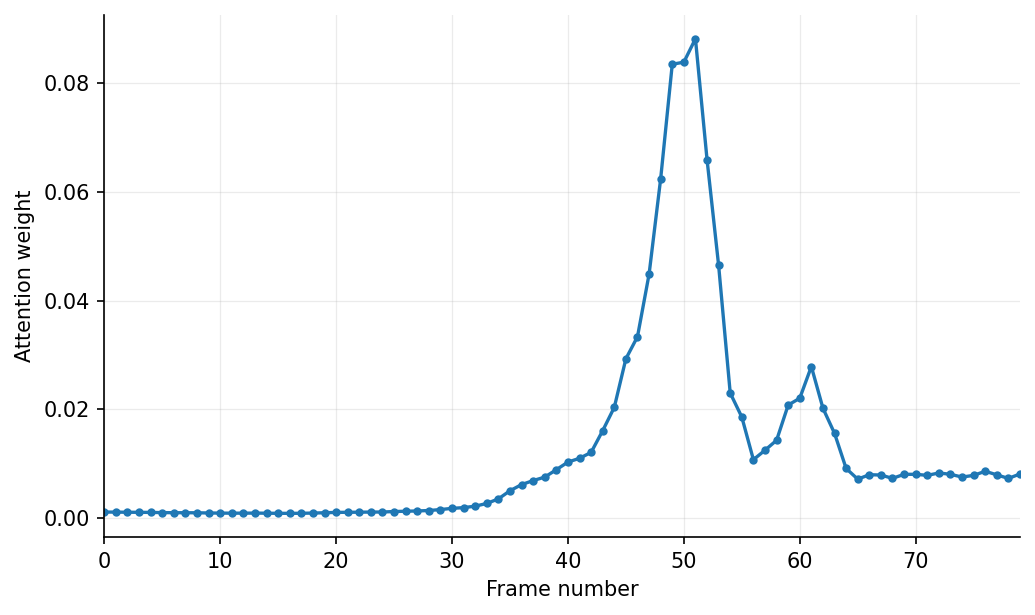

In [3]:
example_shot = 6397 # int(metadata.loc[metadata["category"] == "tp", "Shot"].iloc[0])
fig, ax = ai.plot_attention_scores(data=data, shot=example_shot)
show(fig)

## Overlay a handful of shots

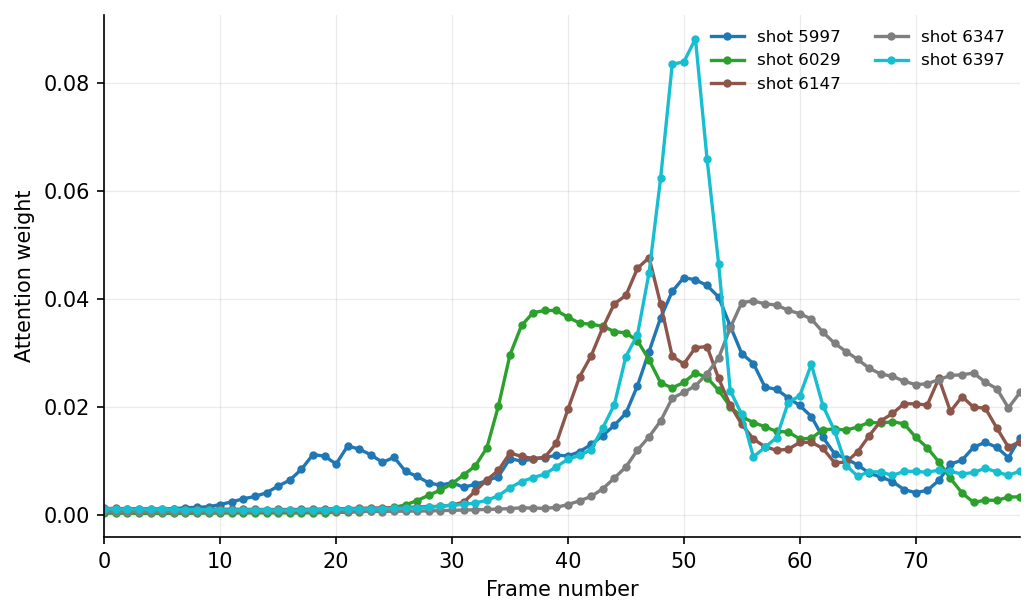

In [4]:
example_shots = metadata.loc[metadata["category"] == "tp", "Shot"].head(5).tolist()
fig, ax = ai.plot_attention_scores(data=data, shots=example_shots, title="True positives (sample)")
show(fig)

## Category-level plots

Saved plot to /u/cmarsden/docs/PPPL/Advanced-Plasmoid-Classification/Image-Data/TimeMIL-output/attention_interpretability/BR_BZ_BY_JY_seed101/plots/category_tp.png


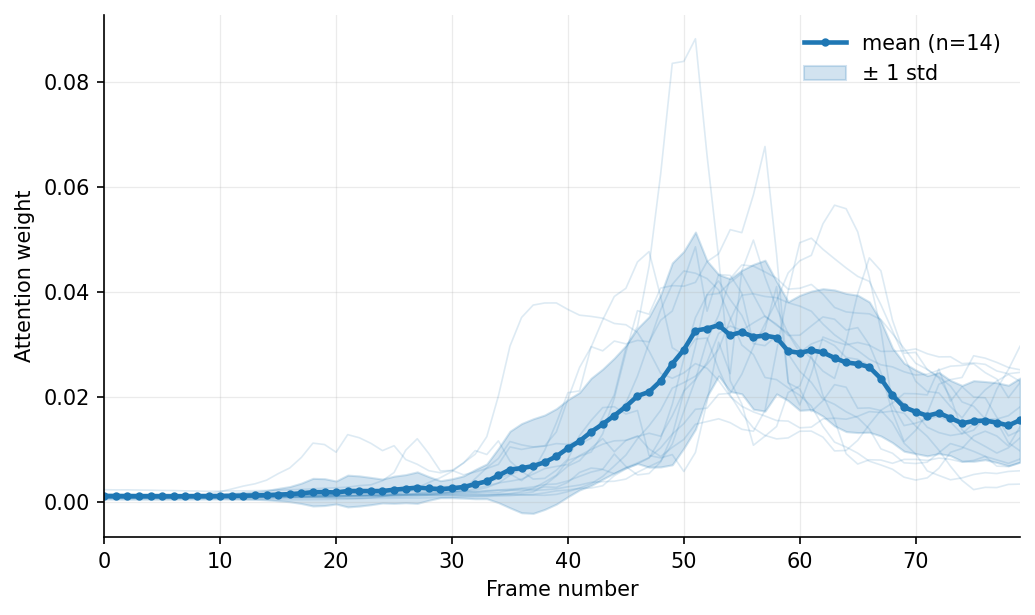

Saved plot to /u/cmarsden/docs/PPPL/Advanced-Plasmoid-Classification/Image-Data/TimeMIL-output/attention_interpretability/BR_BZ_BY_JY_seed101/plots/category_fp.png


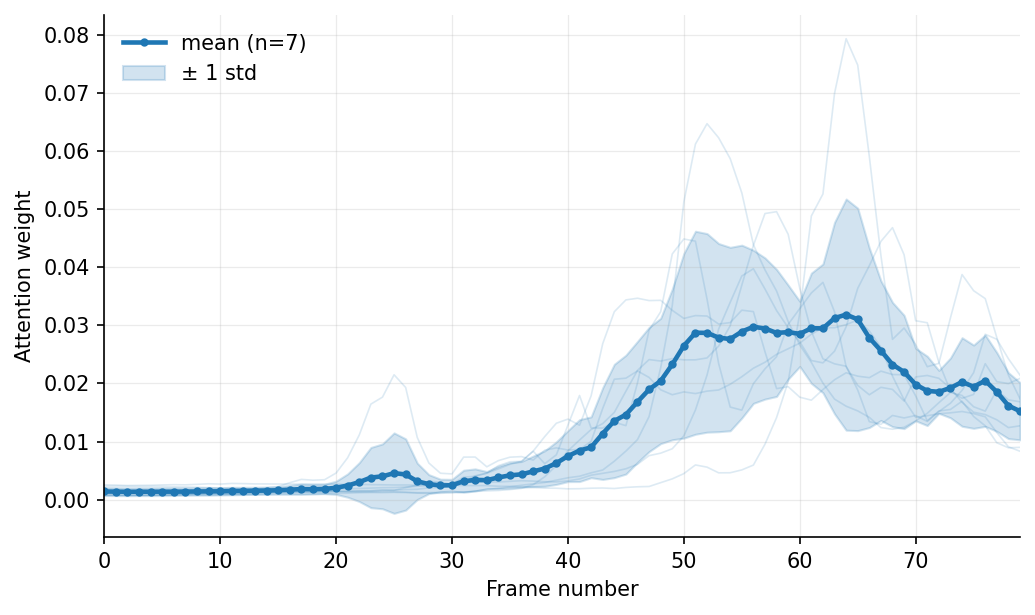

Saved plot to /u/cmarsden/docs/PPPL/Advanced-Plasmoid-Classification/Image-Data/TimeMIL-output/attention_interpretability/BR_BZ_BY_JY_seed101/plots/category_fn.png


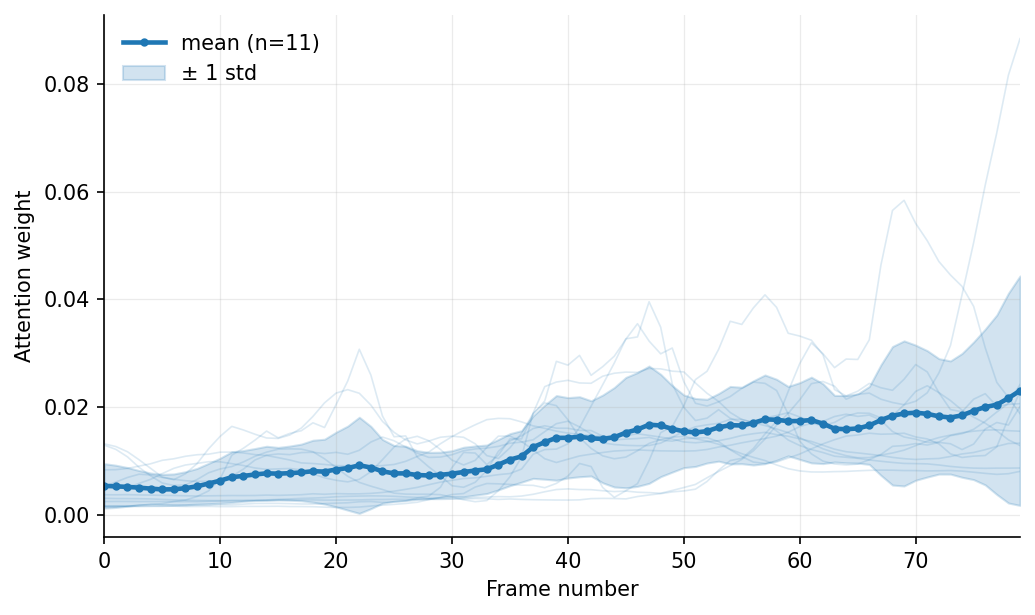

Saved plot to /u/cmarsden/docs/PPPL/Advanced-Plasmoid-Classification/Image-Data/TimeMIL-output/attention_interpretability/BR_BZ_BY_JY_seed101/plots/category_tn.png


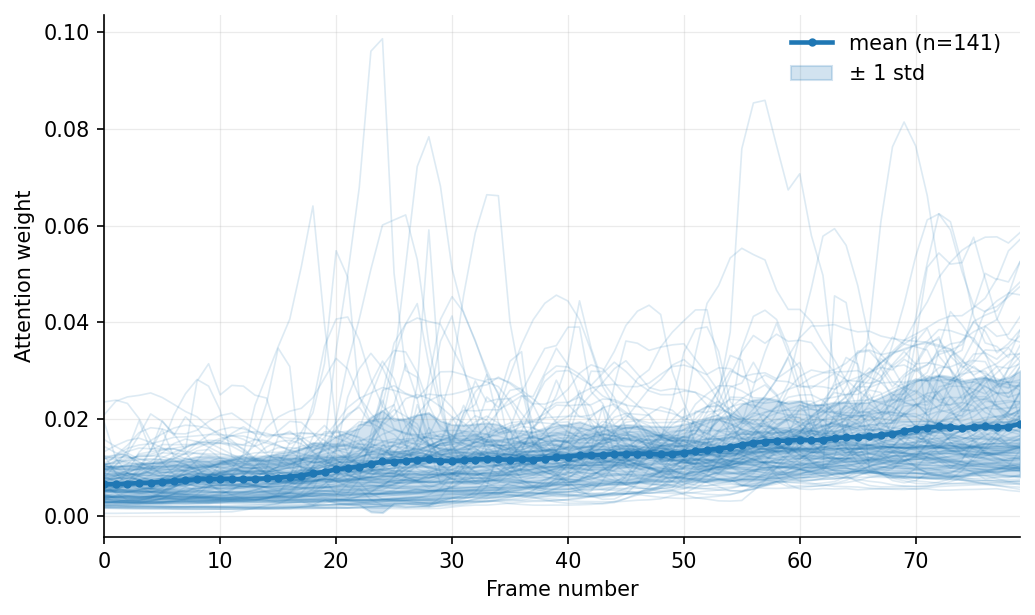

In [5]:
plots_dir = RESULTS_DIR / "plots"

for category in ["tp", "fp", "fn", "tn"]:
    if not (metadata["category"] == category).any():
        print(f"skipping {category}: no test shots in this category")
        continue
    fig, ax = ai.plot_attention_scores(data=data, category=category,
                                        output_path=plots_dir / f"category_{category}.png")
    show(fig)

## All test shots together

Saved plot to /u/cmarsden/docs/PPPL/Advanced-Plasmoid-Classification/Image-Data/TimeMIL-output/attention_interpretability/BR_BZ_BY_JY_seed101/plots/category_all.png


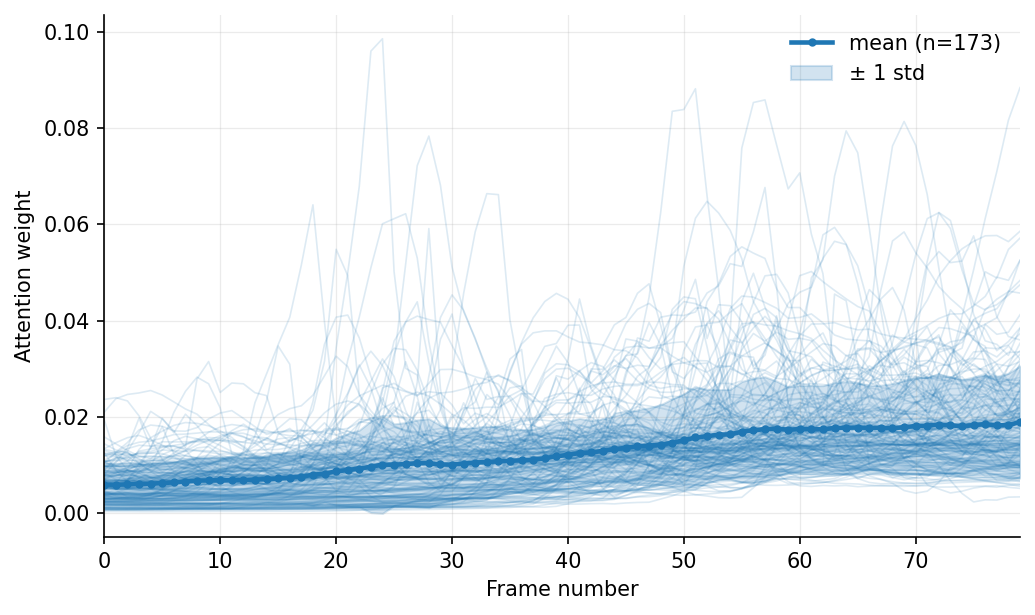

In [6]:
fig, ax = ai.plot_attention_scores(data=data, category="all", output_path=plots_dir / "category_all.png")
show(fig)

---

## Low- vs high-attention raw spatial maps

In [ ]:
FRAME_SHOT = 6397 # any Shot present in metadata["Shot"]
N_FRAMES = 10
FRAME_STRIDE_US = 2.0

low_start = 30 # first N_FRAMES frames of the window (261us onward)
high_start = 45 # hand-picked from the attention-vs-frame plots above; edit as needed

### All four channels, 3 + gap + 3 columns

Saved plot to /u/cmarsden/docs/PPPL/Advanced-Plasmoid-Classification/Image-Data/TimeMIL-output/attention_interpretability/BR_BZ_BY_JY_seed101/plots/shot6397_all_channels_low_vs_high.png


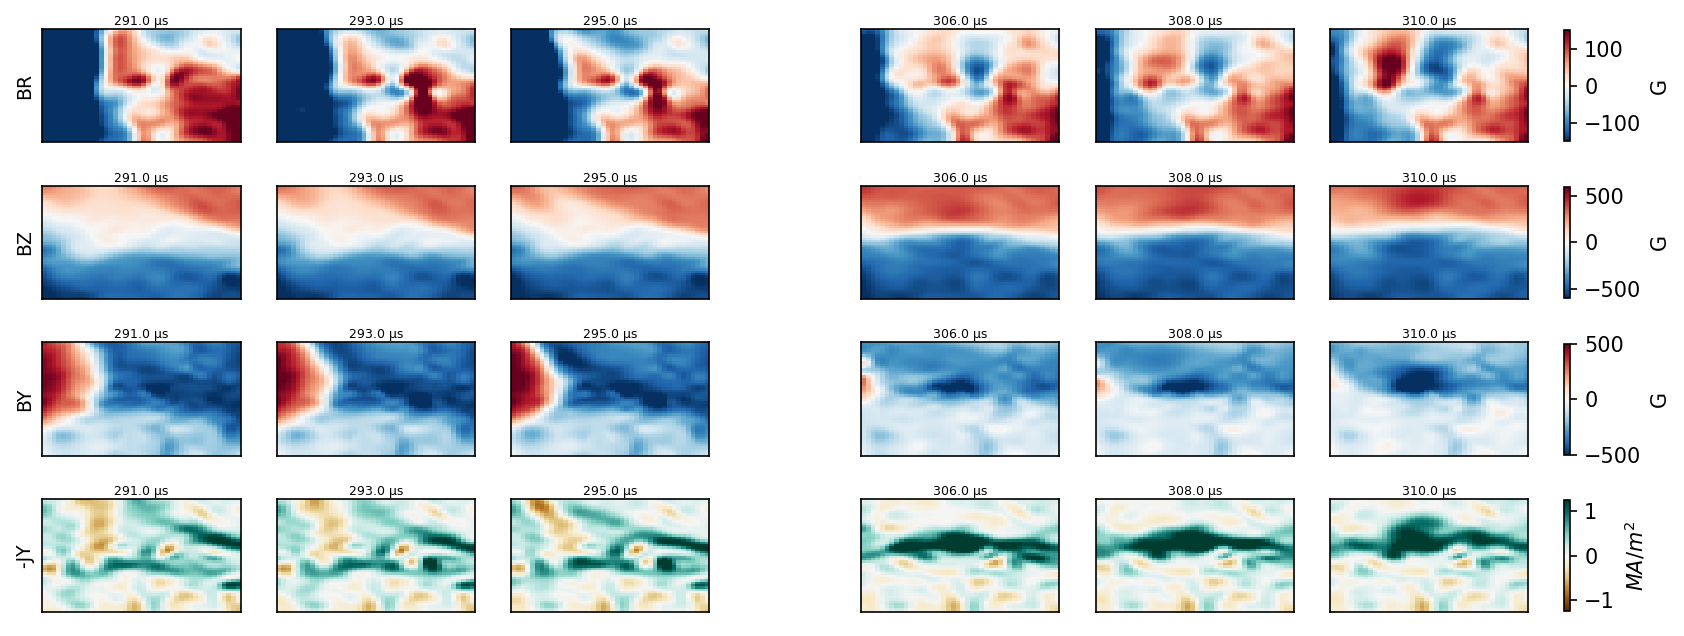

In [20]:
fig, axes = ai.plot_shot_multichannel_frame_grid(
    FRAME_SHOT, high_start_frame=high_start, low_start_frame=low_start,
    n_frames=3, frame_stride_us=FRAME_STRIDE_US,
    output_path=plots_dir / f"shot{FRAME_SHOT}_all_channels_low_vs_high.png",
)
show(fig)

### Attention curve with the low/high windows shaded

Same low_start/high_start windows as the 3 + gap + 3 grid above (n_frames=3), shaded
directly on the attention-vs-frame curve for easy cross-reference.

Saved plot to /u/cmarsden/docs/PPPL/Advanced-Plasmoid-Classification/Image-Data/TimeMIL-output/attention_interpretability/BR_BZ_BY_JY_seed101/plots/shot6397_attention_shaded.png


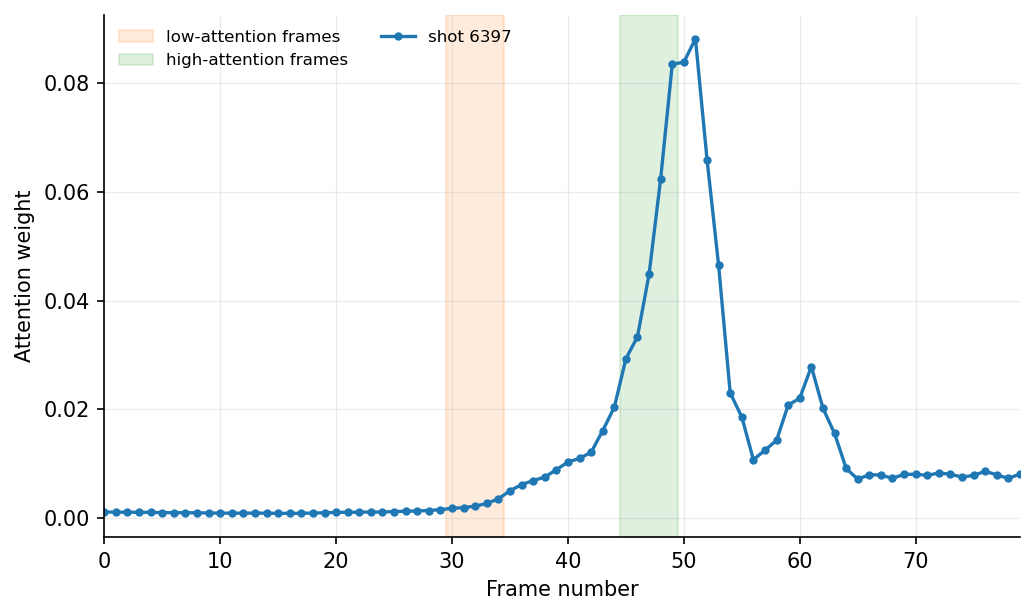

In [9]:
fig, ax = ai.plot_attention_scores(
    data=data, shot=FRAME_SHOT, low_start_frame=low_start, high_start_frame=high_start,
    n_frames=3, frame_stride_us=FRAME_STRIDE_US,
    output_path=plots_dir / f"shot{FRAME_SHOT}_attention_shaded.png",
)
show(fig)

In [19]:
# Rerun after editing attention_interpretability.py (e.g. FIELD_PLOT_CONFIGS clim)
import importlib
importlib.reload(ai)

<module 'attention_interpretability' from '/u/cmarsden/docs/PPPL/MIL-Plasmoid-Classification/Interpretability/attention_interpretability.py'>